d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Number of clusters formed: 2
Amount of noise points: 0


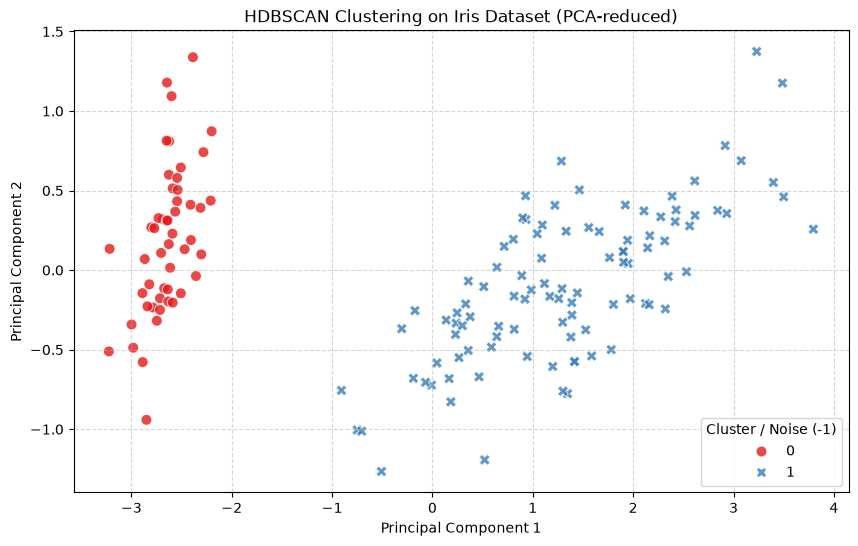

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names

# 2. Perform clustering using HDBSCAN
hdb = HDBSCAN(min_cluster_size=15, min_samples=5)
cluster_labels = hdb.fit_predict(X)

# 3. Report results
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)

print(f"Number of clusters formed: {n_clusters}")
print(f"Amount of noise points: {n_noise}")

# 4. Dimensionality reduction using PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

df_vis = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
df_vis['HDBSCAN_Cluster'] = cluster_labels
df_vis['True_Label'] = y_true

# Plotting HDBSCAN results
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_vis, 
    x='PCA1', 
    y='PCA2', 
    hue='HDBSCAN_Cluster', 
    palette='Set1', 
    style='HDBSCAN_Cluster',
    s=60, 
    alpha=0.8
)
plt.title('HDBSCAN Clustering on Iris Dataset (PCA-reduced)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Cluster / Noise (-1)')
plt.savefig('hdbscan_iris_plot.png', bbox_inches='tight')
plt.show()